# 基于 WOE 与逻辑回归的贷款风险评分卡

个人学习项目 · Kaggle Playground S4E10 · Python

数据为合成竞赛数据，标签 1 统一称为风险事件。

## 0. 导入库

核心建模为第 1—12 节，后续为结果评估与学习扩展。

In [ ]:
%matplotlib inline
from pathlib import Path
import matplotlib

IN_NOTEBOOK = "get_ipython" in globals()
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # 如果在py文件中运行，设置agg，为了不弹图片窗口

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import scorecardpy as sc

# 中文字体。
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd() #确定项目根目录
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
TABLE_DIR = ROOT / "reports" / "tables"
OUTPUT_DIR = ROOT / "outputs"
for directory in (FIG_DIR, TABLE_DIR, OUTPUT_DIR):
    directory.mkdir(parents=True, exist_ok=True)#

def finish_plot(filename=None):
    """精选图（传了名字）保存到 reports内，否则在notebook中显示或不显示。"""
    if filename:
        plt.savefig(FIG_DIR / filename, dpi=150, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close("all")

target = "loan_status"   # 将标签 1 作为风险事件。

## 1. 读取数据

有标签数据与竞赛测试集分开读取。测试集没有标签，不用于报告 AUC/KS。数据来源与字段解释见 [数据说明](data/README.md)。

In [2]:
df_train = pd.read_csv(DATA_DIR / "train.csv")
df_test = pd.read_csv(DATA_DIR / "test.csv")

## 2. 数据概览（EDA）

EDA 先检查样本规模、缺失、重复和明显不合理的年龄/工龄。标签 1 占比约 14.24%。本版保留异常记录以维持原始基线，不根据验证集效果反复修改清洗规则。

In [ ]:
df_train.info()                                            # 查看整体数据情况
num_fea = df_train.drop(columns=["id", target]).select_dtypes(exclude="object").columns  # 数值型特征
obj_fea = df_train.select_dtypes(include="object").columns  # 类别型特征
print("\n唯一值个数：")
print(df_train.nunique())
print("\n有缺失值的列数：", df_train.isnull().any().sum())  # 入门级数据，无缺失值

feature_cols = [c for c in df_train.columns if c not in ["id", target]]
assert df_train["id"].is_unique and df_test["id"].is_unique
assert set(df_train[target].unique()) == {0, 1}
assert set(df_test.columns) == set(df_train.columns) - {target}
quality_rows = []
for name, frame in [("labeled", df_train), ("test", df_test)]:
    quality_rows.append({
        "dataset": name, "rows": len(frame),
        "missing_cells": int(frame.isna().sum().sum()),
        "duplicate_features": int(frame.duplicated(feature_cols).sum()),
        "age_over_100": int((frame.person_age > 100).sum()),
        "employment_exceeds_age": int((frame.person_emp_length > frame.person_age).sum()),
    })
quality_report = pd.DataFrame(quality_rows)
print(quality_report.to_string(index=False))
print("标签 1 占比：", df_train[target].mean())
# 合成数据中的异常值保留在基线中，且由分箱吸收。

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          58645 non-null  int64  
 1   person_age                  58645 non-null  int64  
 2   person_income               58645 non-null  int64  
 3   person_home_ownership       58645 non-null  object 
 4   person_emp_length           58645 non-null  int64  
 5   loan_intent                 58645 non-null  object 
 6   loan_grade                  58645 non-null  object 
 7   loan_amnt                   58645 non-null  int64  
 8   loan_int_rate               58645 non-null  float64
 9   loan_percent_income         58645 non-null  float64
 10  cb_person_default_on_file   58645 non-null  object 
 11  cb_person_cred_hist_length  58645 non-null  int64  
 12  loan_status                 58645 non-null  int64  
dtypes: float64(2), int64(7), object

## 3. 数值型变量分布

观察偏态、取值范围及离散程度。ID 和标签不作为连续特征画分布。

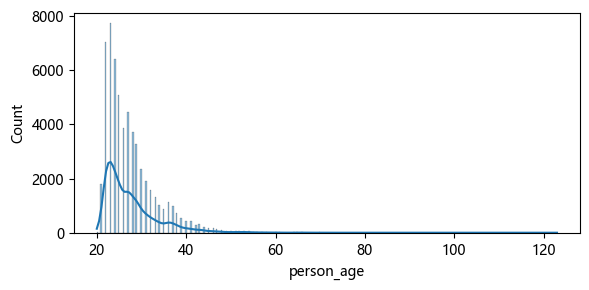

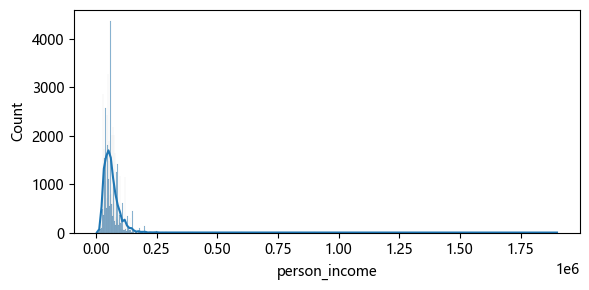

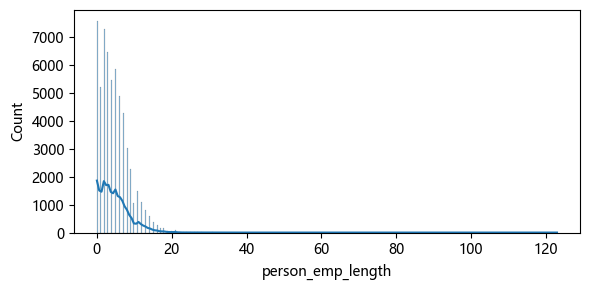

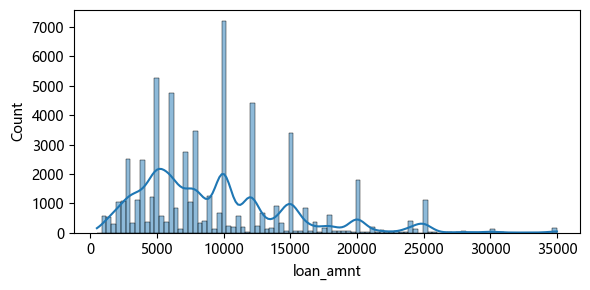

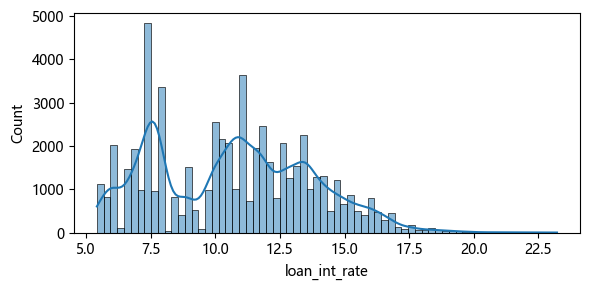

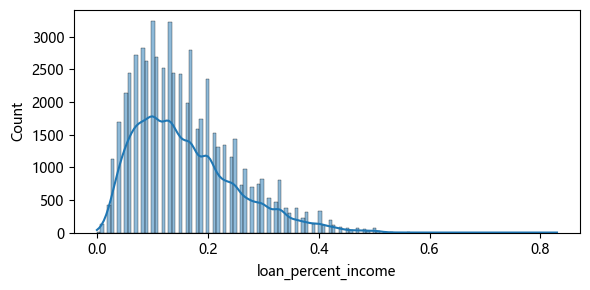

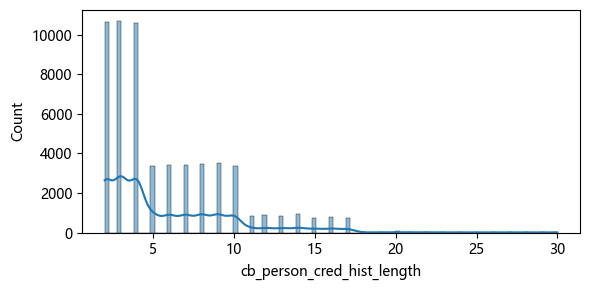

In [4]:
for col in num_fea:
    plt.figure(figsize=(6, 3))
    sns.histplot(df_train[col], kde=True)
    plt.tight_layout()
    finish_plot()

## 4. 类别型变量分布

类别频数用于了解样本结构。WOE 会用训练集标签估计各分箱的风险信息。

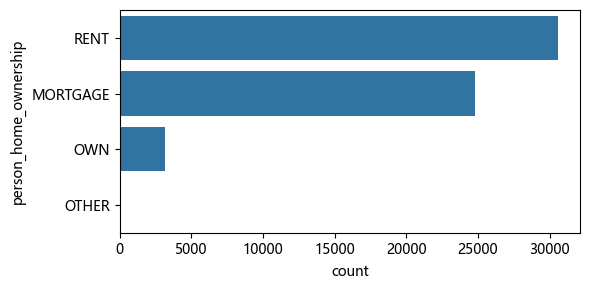

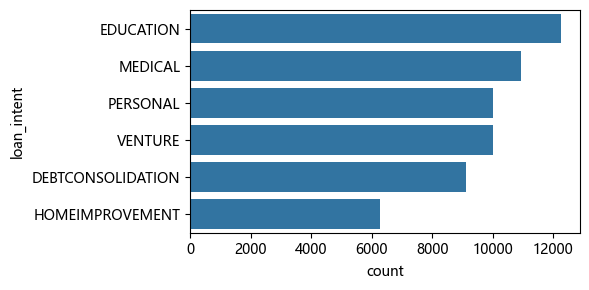

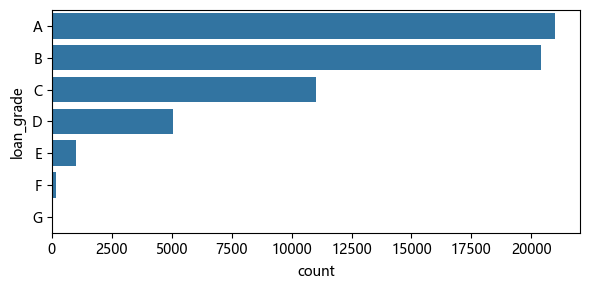

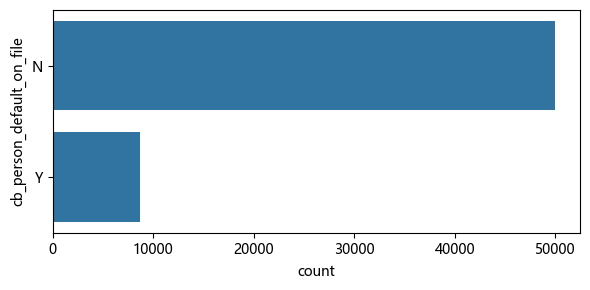

In [5]:
for col in obj_fea:
    plt.figure(figsize=(6, 3))
    sns.countplot(data=df_train, y=col, order=df_train[col].value_counts().index)
    plt.tight_layout()
    finish_plot()

## 5. 划分训练集 / 验证集（stratify 保证标签 1 样本比例一致）

先按标签分层划分 80% 训练集和 20% 验证集，固定随机种子 42，再仅用训练集拟合分箱。训练集 46,916 条，验证集 11,729 条。没有先用全量标签生成 WOE。

[INFO] creating woe binning ...


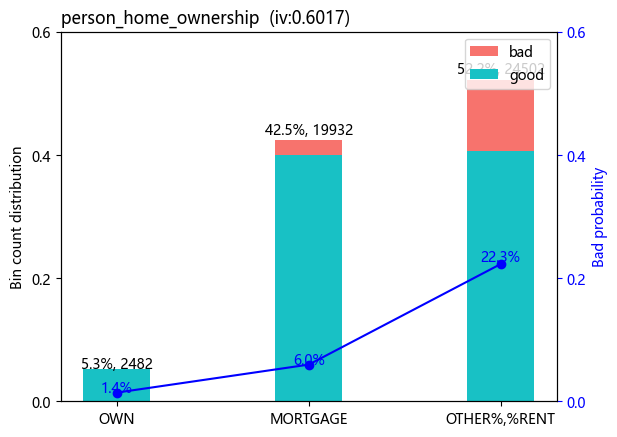

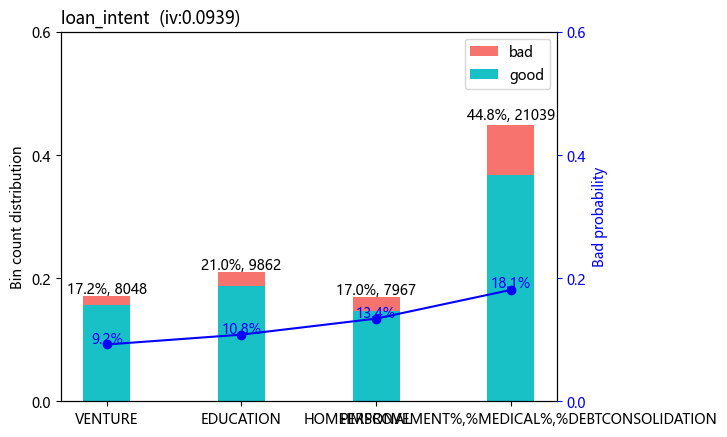

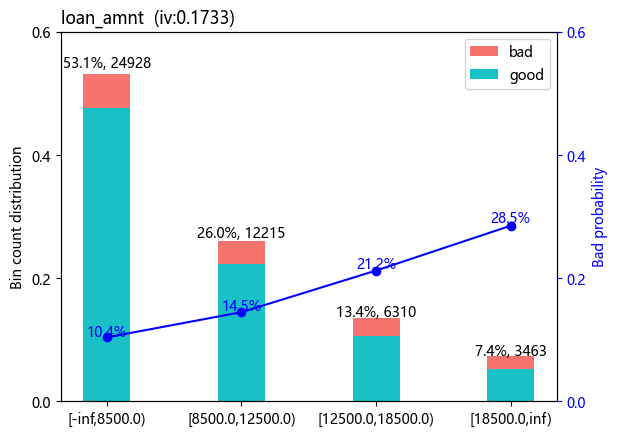

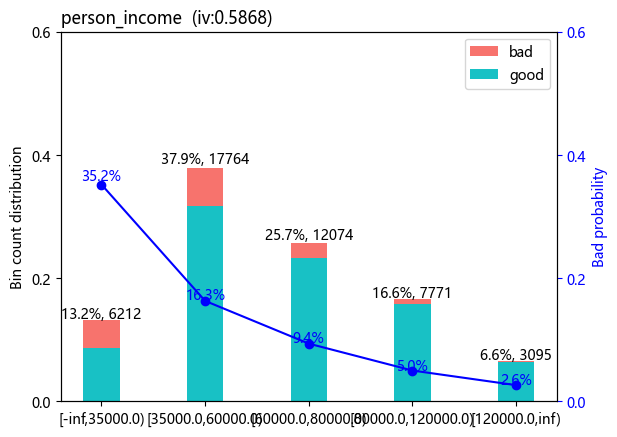

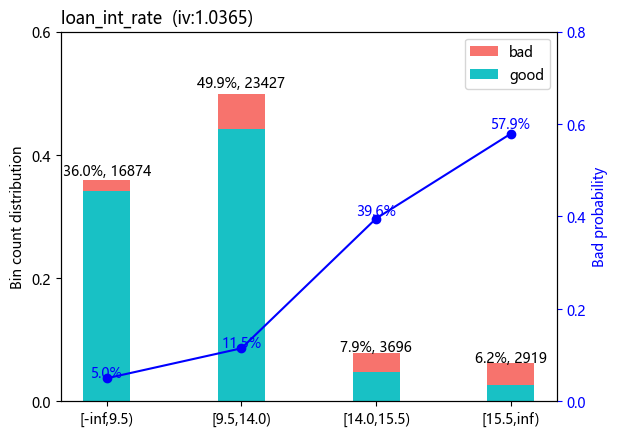

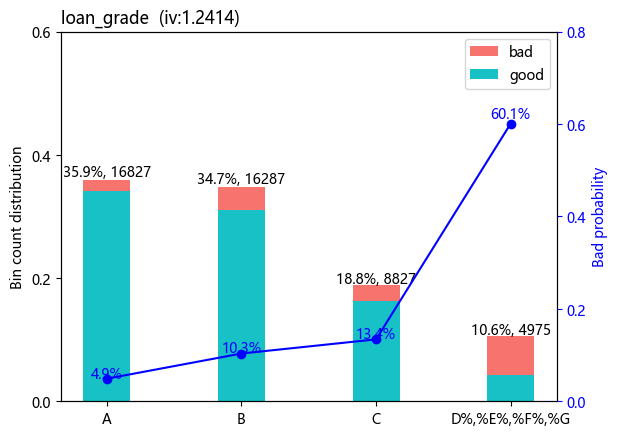

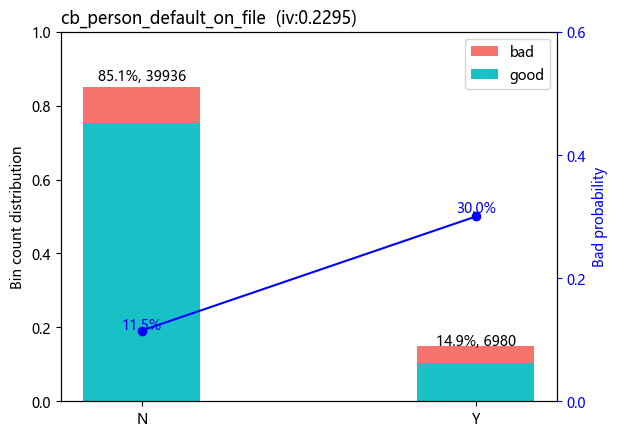

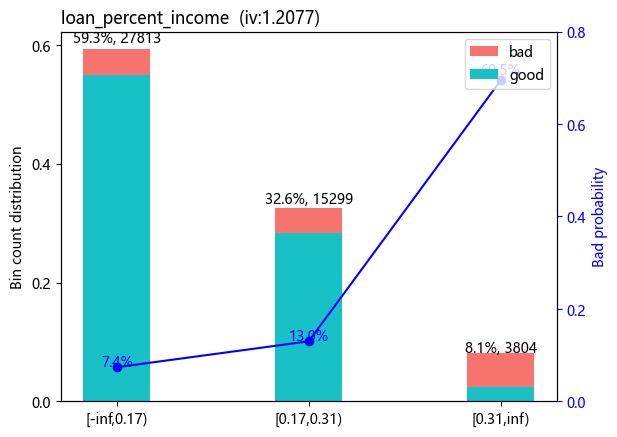

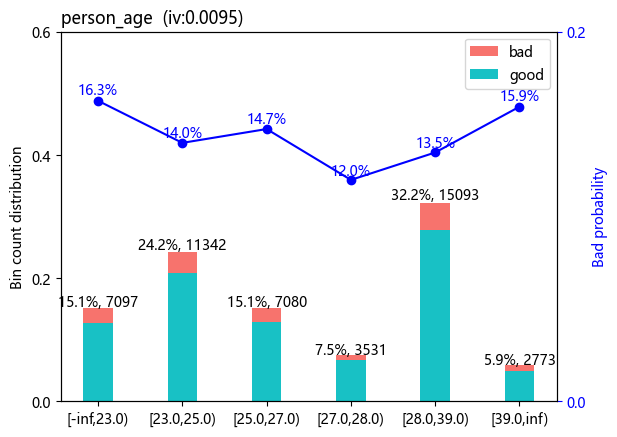

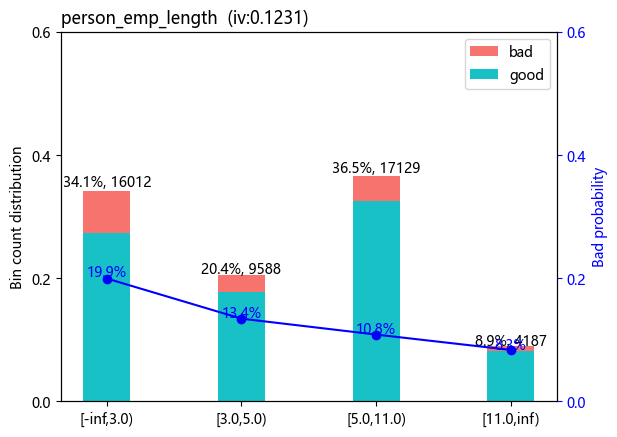

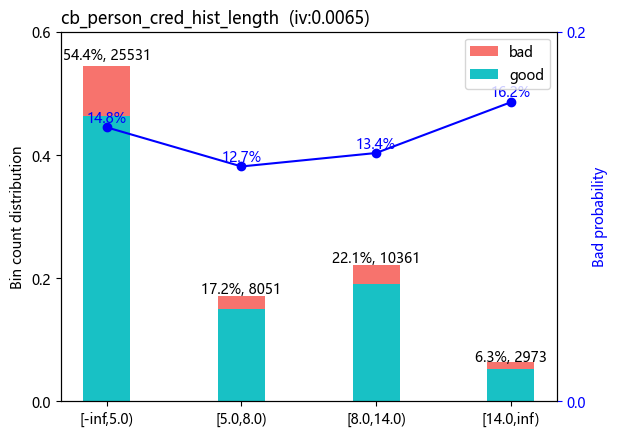

In [6]:
df_train, df_valid = train_test_split(
    df_train, test_size=0.2, random_state=42, stratify=df_train[target]
)

# 自动分箱（决策树分箱），并画分箱图
# 注意：去掉 id 列，id 是主键，不应参与分箱与建模
bins = sc.woebin(df_train.drop(columns=["id"]), y=target)
if IN_NOTEBOOK:
    sc.woebin_plot(bins)
    finish_plot()

## 6. WOE 编码（train / valid / test 都用同一套分箱规则）

三个集合使用同一套训练集分箱规则。scorecardpy 的 WOE 采用标签 1/标签 0 分布比的对数；不与另一种相反符号的定义混用。

In [7]:
train_woe = sc.woebin_ply(df_train.drop(columns=["id"]), bins)
valid_woe = sc.woebin_ply(df_valid.drop(columns=["id"]), bins)
test_woe = sc.woebin_ply(df_test.drop(columns=["id"]), bins)

# 清理可能的空列 / 无名列
bad_cols = [c for c in train_woe.columns if c == "" or "Unnamed" in str(c) or c == "index"]
train_woe = train_woe.drop(columns=bad_cols)
valid_woe = valid_woe.drop(columns=bad_cols)
test_woe = test_woe.drop(columns=bad_cols)
print("\nWOE 编码后的前 5 行：")
print(train_woe.head())

[INFO] converting into woe values ...


[INFO] converting into woe values ...


[INFO] converting into woe values ...



WOE 编码后的前 5 行：
       loan_status  person_home_ownership_woe  loan_intent_woe  loan_amnt_woe  \
18548            0                  -2.451626         0.284113       0.483946   
24867            1                  -0.963854         0.284113       0.018517   
55557            0                  -2.451626        -0.491458      -0.360281   
19667            0                  -0.963854         0.284113      -0.360281   
36857            0                   0.545974         0.284113       0.018517   

       person_income_woe  loan_int_rate_woe  loan_grade_woe  \
18548          -0.474930          -0.247995       -0.070223   
24867           0.159351           2.114172        2.205299   
55557           1.184944          -0.247995       -0.364411   
19667           0.159351          -0.247995       -0.364411   
36857          -0.474930          -1.152169       -1.171994   

       cb_person_default_on_file_woe  loan_percent_income_woe  person_age_woe  \
18548                      -0.246646 

## 7. 构造特征矩阵与标签

标签和 ID 不进入特征矩阵。固定列顺序，使逐步筛选遇到数值上相同的 p 值时具有确定的处理顺序。

In [ ]:
# 记录并固定列顺序
woe_columns = [f"{c}_woe" for c in feature_cols]
x_train = train_woe[woe_columns]
y_train = train_woe[target]
x_valid = valid_woe[woe_columns]
y_valid = valid_woe[target]
x_test = test_woe[woe_columns]

## 8. 相关性分析：移除信息高度重叠的贷款等级

其 WOE 与贷款利率 WOE 的训练集相关系数约为 0.913，二者信息高度重叠，且经过后续vif查看模型具有多重共线性，删除grade后vif正常

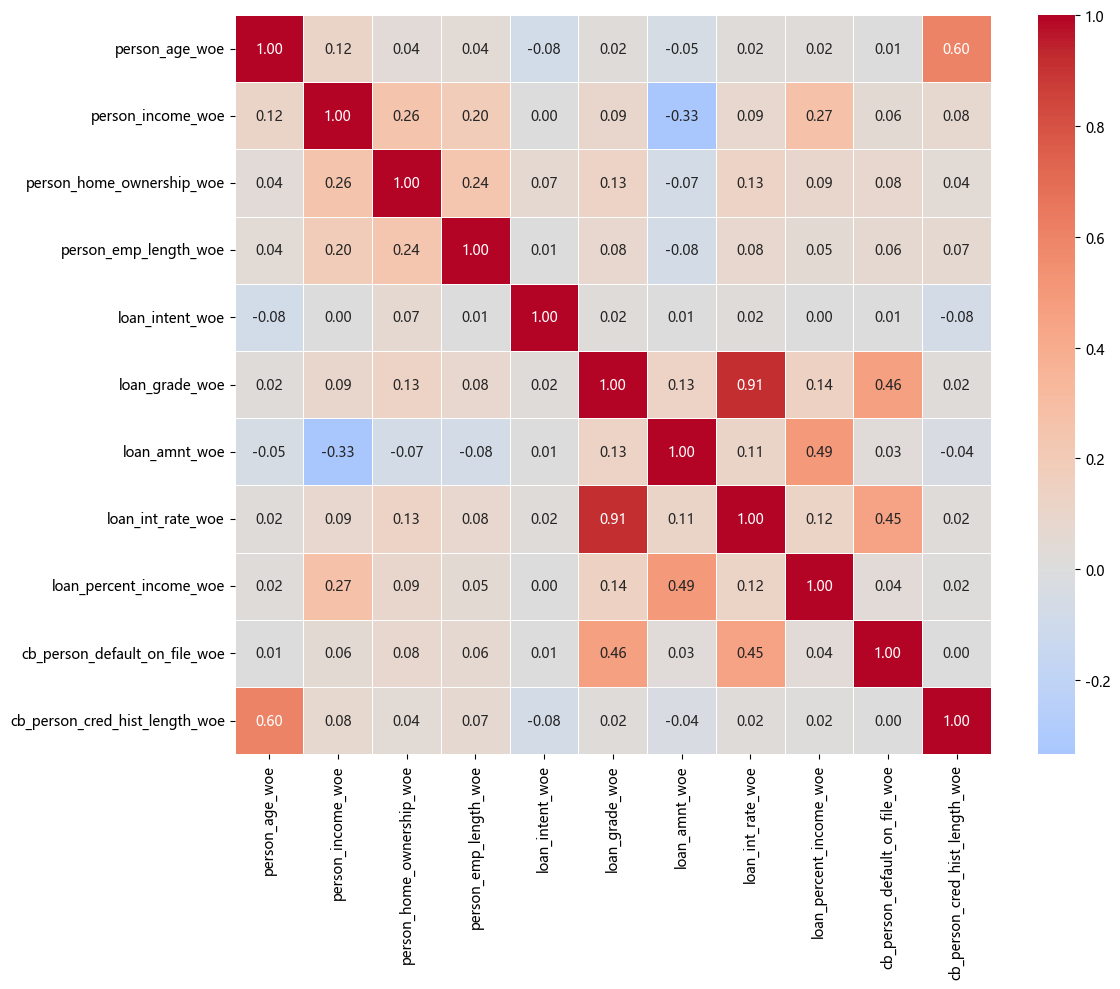

等级与利率 WOE 相关系数： 0.9128664807200493


In [9]:
corr = x_train.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", linewidths=0.5)
plt.tight_layout()
finish_plot()
print("等级与利率 WOE 相关系数：", corr.loc["loan_grade_woe", "loan_int_rate_woe"])
x_train = x_train.drop(columns="loan_grade_woe")  # 本数据中二者相关系数约 0.913。

## 9. VIF 多重共线性检验


In [ ]:
vif = pd.DataFrame()
vif["feature"] = x_train.columns
vif_design = sm.add_constant(x_train)
vif["vif"] = [variance_inflation_factor(vif_design.values, i + 1) for i in range(len(x_train.columns))]
vif["iv"] = [bins[col.replace("_woe", "")]["total_iv"].iloc[0] for col in x_train.columns]
print(vif)

                          feature       vif        iv
0                  person_age_woe  1.586117  0.009461
1               person_income_woe  1.675359  0.586792
2       person_home_ownership_woe  1.131575  0.601702
3           person_emp_length_woe  1.087415  0.123055
4                 loan_intent_woe  1.012808  0.093889
5                   loan_amnt_woe  1.937443  0.173344
6               loan_int_rate_woe  1.301951  1.036472
7         loan_percent_income_woe  1.834424  1.207675
8   cb_person_default_on_file_woe  1.258461  0.229486
9  cb_person_cred_hist_length_woe  1.577113  0.006547


## 10. 逐步回归变量筛选（向前加入 + 向后剔除）

WOE 和筛选均使用训练标签。

In [11]:
def stepwise_selection(X, y, p_enter=0.05, p_remove=0.05, verbose=True):
    """输入特征与标签，用 p 值做逐步回归，返回被选中的变量名列表。"""
    included = []
    visited = set()
    while True:
        state = tuple(sorted(included))
        if state in visited:
            raise RuntimeError("逐步筛选发生循环，请检查候选变量和阈值。")
        visited.add(state)
        changed = False
        # 向前：尝试加入一个 p 值最小的变量
        excluded = [c for c in X.columns if c not in included]
        pvals = {}
        for c in excluded:
            model = sm.Logit(y, sm.add_constant(X[included + [c]])).fit(disp=0)
            pvals[c] = model.pvalues[c]
        if pvals:
            best = min(pvals, key=lambda c: (pvals[c], list(X.columns).index(c)))
            if pvals[best] < p_enter:
                included.append(best)
                changed = True
                if verbose:
                    print(f"加入：{best} (p={pvals[best]:.6f})")
        # 向后：尝试剔除一个 p 值最大的变量
        if included:
            model = sm.Logit(y, sm.add_constant(X[included])).fit(disp=0)
            pvals = model.pvalues.drop("const", errors="ignore")
            worst = pvals.idxmax()
            if pvals[worst] > p_remove:
                included.remove(worst)
                changed = True
                if verbose:
                    print(f"剔除：{worst} (p={pvals[worst]:.4f})")
        if not changed:
            break
    return included

selected_vars = stepwise_selection(x_train, y_train)
print("\n逐步回归选出的变量：", selected_vars)

加入：person_income_woe (p=0.000000)


加入：loan_amnt_woe (p=0.000000)


加入：loan_int_rate_woe (p=0.000000)


加入：loan_percent_income_woe (p=0.000000)
剔除：loan_amnt_woe (p=0.1758)


加入：person_home_ownership_woe (p=0.000000)


...

加入：person_emp_length_woe (p=0.000000)


加入：cb_person_default_on_file_woe (p=0.000100)


加入：person_age_woe (p=0.000401)


加入：loan_amnt_woe (p=0.038969)



逐步回归选出的变量： ['person_income_woe', 'loan_int_rate_woe', 'loan_percent_income_woe', 'person_home_ownership_woe', 'loan_intent_woe', 'person_emp_length_woe', 'cb_person_default_on_file_woe', 'person_age_woe', 'loan_amnt_woe']


## 11. 逻辑回归建模

AUC 衡量二分类排序正负样本区分度，KS 衡量两类累计分布的极差。

In [12]:
clf = LogisticRegression(penalty="l2", C=1.0, solver="lbfgs", max_iter=100, random_state=42)
clf.fit(x_train[selected_vars], y_train)

print("\nWOE 线性系数：", dict(zip(selected_vars, clf.coef_[0])))
print("截距：", clf.intercept_)


def evaluate(model, X, y, name="valid"):
    """输入模型、特征与标签，打印 AUC / KS，返回预测的标签 1 概率。"""
    prob = model.predict_proba(X[selected_vars])[:, 1]   # y=1 的标签 1 概率
    auc = roc_auc_score(y, prob)
    fpr, tpr, _ = roc_curve(y, prob)
    ks = max(tpr - fpr)
    print(f"[{name}] AUC = {auc:.4f}, KS = {ks:.4f}")
    return prob

train_prob = evaluate(clf, x_train, y_train, "train")
valid_prob = evaluate(clf, x_valid, y_valid, "valid")


WOE 线性系数： {'person_income_woe': np.float64(0.6143377795776753), 'loan_int_rate_woe': np.float64(1.185048444521069), 'loan_percent_income_woe': np.float64(1.1007142530439198), 'person_home_ownership_woe': np.float64(0.8618337876195844), 'loan_intent_woe': np.float64(1.477761177049113), 'person_emp_length_woe': np.float64(0.5286696618378799), 'cb_person_default_on_file_woe': np.float64(0.14636501011170341), 'person_age_woe': np.float64(0.6224635616706584), 'loan_amnt_woe': np.float64(0.12852883249585645)}
截距： [-1.93174569]
[train] AUC = 0.9069, KS = 0.6664
[valid] AUC = 0.9091, KS = 0.6820


## 12. 生成评分卡

评分转换为 $S=A-B\ln[p/(1-p)]$，其中 $B=50/\ln2$，$A=600+B\ln(1/20)$。600 分对应坏/好比 1:20；好/坏比翻倍加 50 分。

In [13]:
POINTS0 = 600      # 基准分数
ODDS0 = 1 / 20     # 基准坏/好比：1 个标签 1 对应 20 个标签 0
PDO = 50           # 好/坏比翻倍时增加的分

card = sc.scorecard(
    bins, clf, xcolumns=selected_vars,
    points0=POINTS0, odds0=ODDS0, pdo=PDO,
)

train_score = sc.scorecard_ply(df_train, card, print_step=0)
valid_score = sc.scorecard_ply(df_valid, card, print_step=0)
test_score = sc.scorecard_ply(df_test, card, print_step=0)
print("\n训练集分数前 5 行：")
print(train_score.head())

# 给分数表挂上标签，方便后面按好标签 1 样本分析
train_score["loan_status"] = df_train["loan_status"].values
valid_score["loan_status"] = df_valid["loan_status"].values


训练集分数前 5 行：
       score
18548  707.0
24867  362.0
55557  703.0
19667  619.0
36857  615.0


## 13. 分数分布图（train / valid 快速对比）

比较训练/验证分数分布，检查是否存在明显整体偏移。

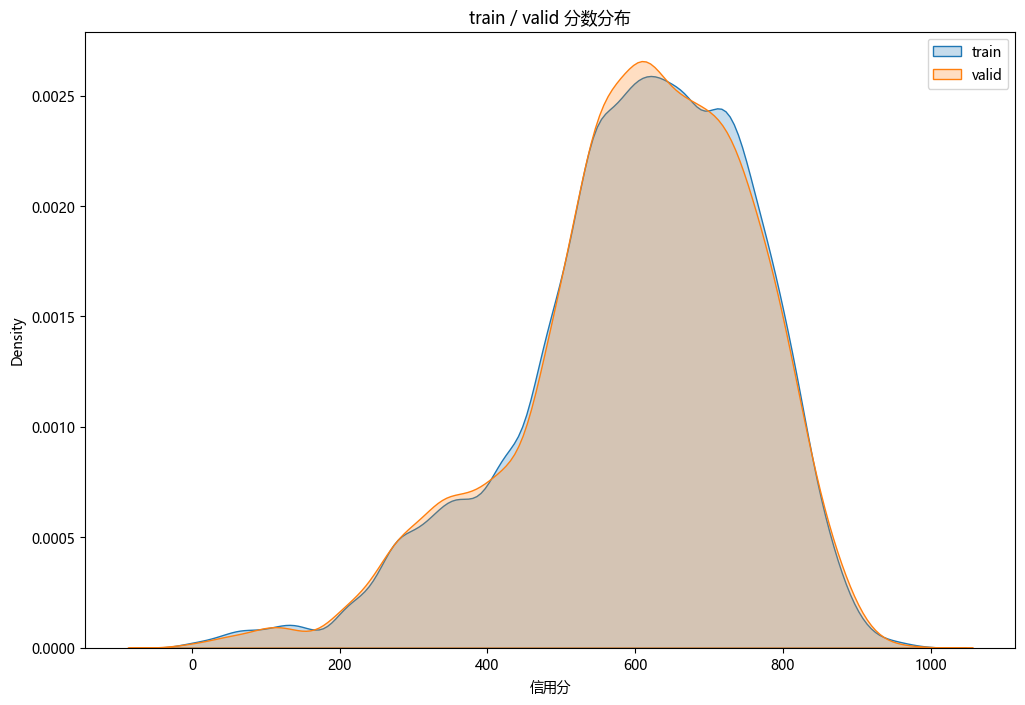

In [14]:
plt.figure(figsize=(12, 8))
sns.kdeplot(train_score["score"], label="train", fill=True)
sns.kdeplot(valid_score["score"], label="valid", fill=True)
plt.xlabel("信用分"); plt.title("train / valid 分数分布")
plt.legend(); finish_plot()

## 14. 评分卡表明细（打印每个变量的分箱与分值）

总分由基础分和各变量所在分箱的分值相加得到。评分卡明细是本项目最直接的可解释输出。

In [15]:
for k, v in card.items():
    print(k)
    print(v)
    print("---")

basepoints
     variable  bin  points
0  basepoints  NaN   523.0
---
person_income
         variable                 bin  points
11  person_income      [-inf,35000.0)   -53.0
12  person_income   [35000.0,60000.0)    -7.0
13  person_income   [60000.0,80000.0)    21.0
14  person_income  [80000.0,120000.0)    51.0
15  person_income      [120000.0,inf)    81.0
---
loan_int_rate
         variable          bin  points
16  loan_int_rate   [-inf,9.5)    98.0
17  loan_int_rate   [9.5,14.0)    21.0
18  loan_int_rate  [14.0,15.5)  -117.0
19  loan_int_rate   [15.5,inf)  -181.0
---
loan_percent_income
               variable          bin  points
26  loan_percent_income  [-inf,0.17)    58.0
27  loan_percent_income  [0.17,0.31)     8.0
28  loan_percent_income   [0.31,inf)  -208.0
---
person_home_ownership
                variable           bin  points
0  person_home_ownership           OWN   152.0
1  person_home_ownership      MORTGAGE    60.0
2  person_home_ownership  OTHER%,%RENT   -34.0
---
loan_i

## 15. 分数分布与坏率（观察整体方向，允许小样本区间波动）

按固定宽度观察训练集坏率。小样本区间会波动，不要求每个区间都严格单调。

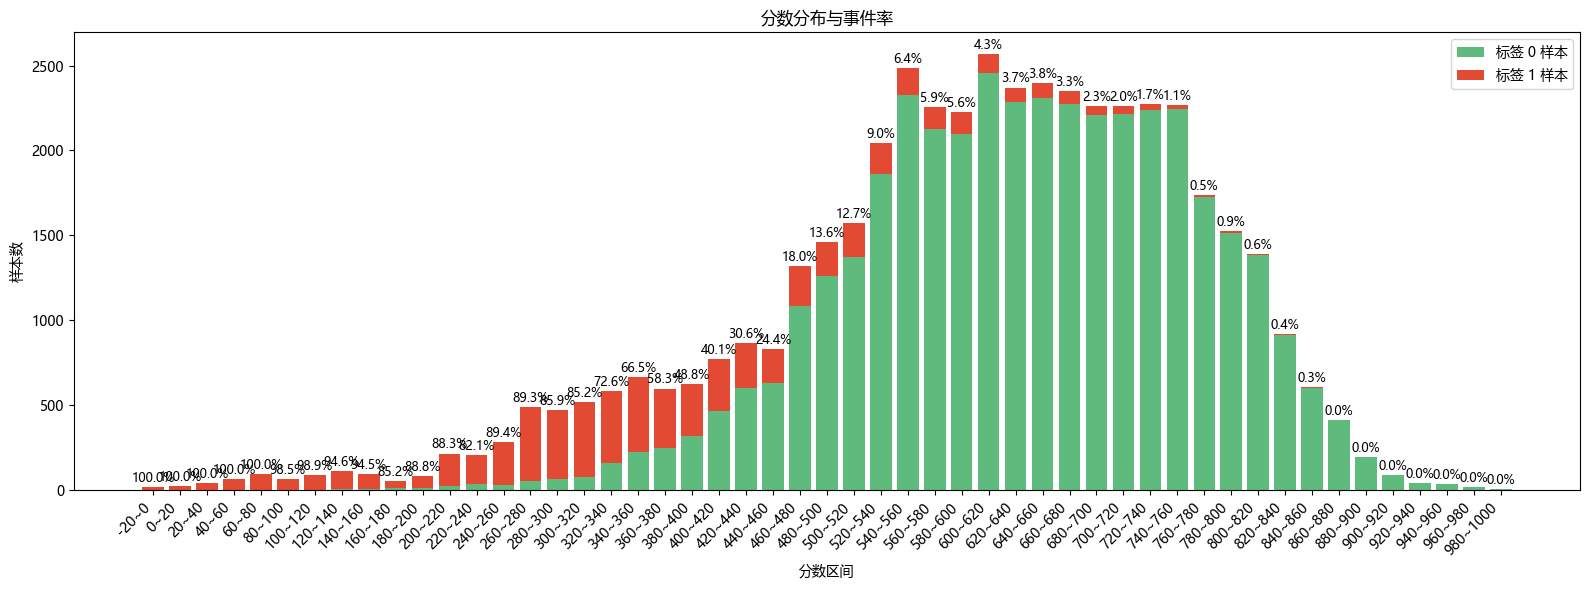

In [ ]:
# 按分数实际范围切成等宽区间（每 20 分一箱），用 matplotlib 画堆叠柱状图
score_min = train_score["score"].min()
score_max = train_score["score"].max()
bin_edges = np.arange(np.floor(score_min / 20) * 20, np.ceil(score_max / 20) * 20 + 1, 20)
train_score["bin"] = pd.cut(train_score["score"], bins=bin_edges, include_lowest=True)

g = train_score.groupby("bin", observed=False)["loan_status"].agg(["count", "sum"])
good = g["count"] - g["sum"]
bad = g["sum"]
xpos = np.arange(len(g))
labels = [f"{iv.left:.0f}~{iv.right:.0f}" for iv in g.index.categories]

plt.figure(figsize=(16, 6))
plt.bar(xpos, good, color="#5FBA7D", label="标签 0 样本")
plt.bar(xpos, bad, bottom=good, color="#E24A33", label="标签 1 样本")
for i in xpos:
    if g["count"].iloc[i] > 0:
        plt.text(i, g["count"].iloc[i] + 30, f"{g['sum'].iloc[i] / g['count'].iloc[i]:.1%}",
                 ha="center", fontsize=9)
plt.xticks(xpos, labels, rotation=45, ha="right")
plt.xlabel("分数区间"); plt.ylabel("样本数")
plt.title("分数分布与事件率"); plt.legend(); plt.tight_layout(); 
finish_plot()

# ====================================================================
# 以下为评估与扩展分析；
# ====================================================================

## 16. 模型评估：KS 曲线



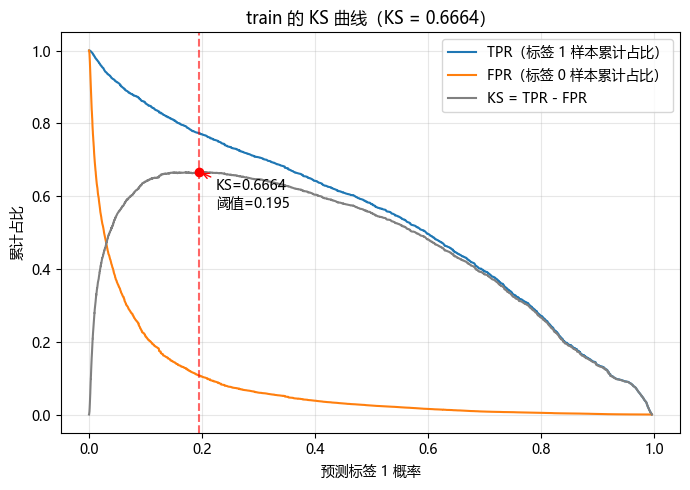

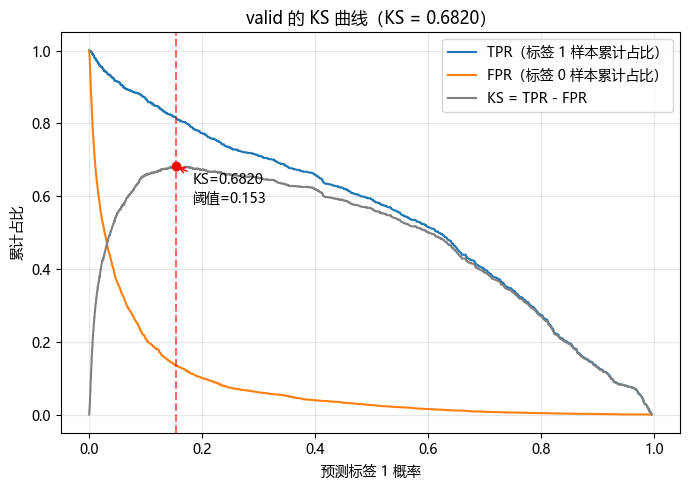

In [17]:
def plot_ks(y_true, y_prob, name="train", save=False):
    """输入真实标签与预测概率，画 KS 曲线并标出最大点，返回 (KS 值, 概率阈值)。"""
    # ROC 按唯一概率阈值聚合，避免相同概率内部排序造成虚假的 KS 点。
    cum_good, cum_bad, prob_sorted = roc_curve(y_true, y_prob, drop_intermediate=False)
    finite = np.isfinite(prob_sorted)
    cum_good, cum_bad, prob_sorted = cum_good[finite], cum_bad[finite], prob_sorted[finite]
    ks_curve = cum_bad - cum_good
    idx = ks_curve.argmax()
    ks, best_thr = ks_curve[idx], prob_sorted[idx]

    plt.figure(figsize=(7, 5))
    plt.plot(prob_sorted, cum_bad, label="TPR（标签 1 样本累计占比）")
    plt.plot(prob_sorted, cum_good, label="FPR（标签 0 样本累计占比）")
    plt.plot(prob_sorted, ks_curve, label="KS = TPR - FPR", color="gray")
    plt.axvline(best_thr, color="red", linestyle="--", alpha=0.6)
    plt.scatter([best_thr], [ks], color="red", zorder=5)
    plt.annotate(f"KS={ks:.4f}\n阈值={best_thr:.3f}",
                 xy=(best_thr, ks), xytext=(best_thr + 0.03, ks - 0.1),
                 arrowprops=dict(arrowstyle="->", color="red"))
    plt.xlabel("预测标签 1 概率"); plt.ylabel("累计占比")
    plt.title(f"{name} 的 KS 曲线（KS = {ks:.4f}）")
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    if save:
        plt.savefig(FIG_DIR / f"{name}_ks.png", dpi=150, bbox_inches="tight")
    finish_plot()
    return ks, best_thr

train_ks, train_ks_thr = plot_ks(y_train, train_prob, "train", save=True)
valid_ks, valid_ks_thr = plot_ks(y_valid, valid_prob, "valid", save=True)

## 17. 模型评估：分数十分位分箱（坏率 + lift）

训练集确定边界，验证集沿用，因此验证集各组人数不必相等。Lift = 组内坏率 / 本集合坏率。

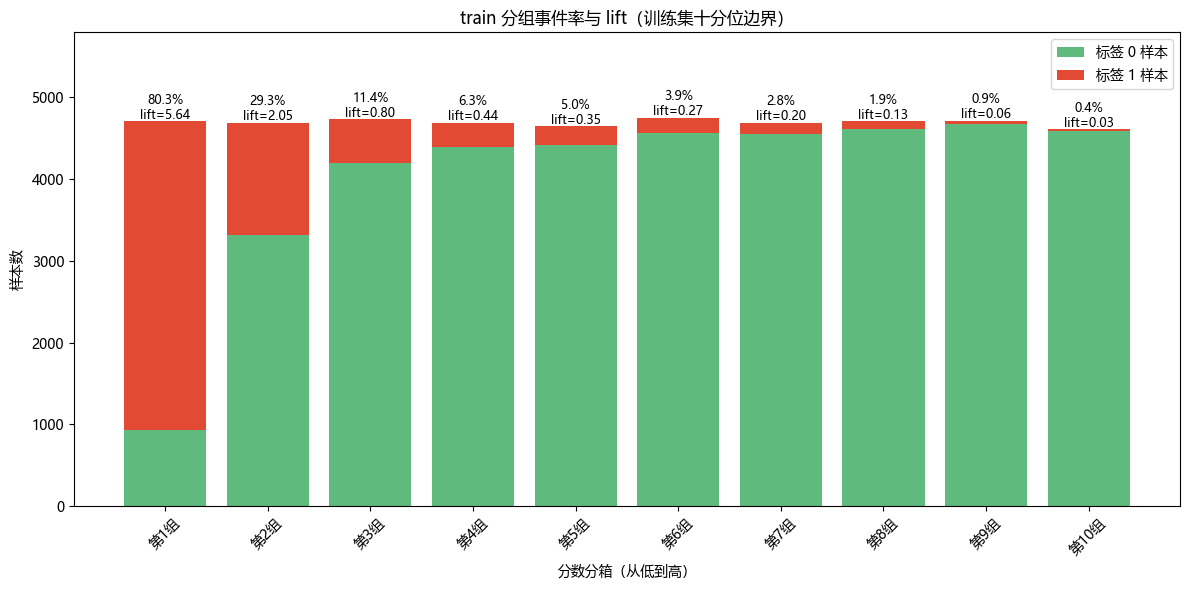

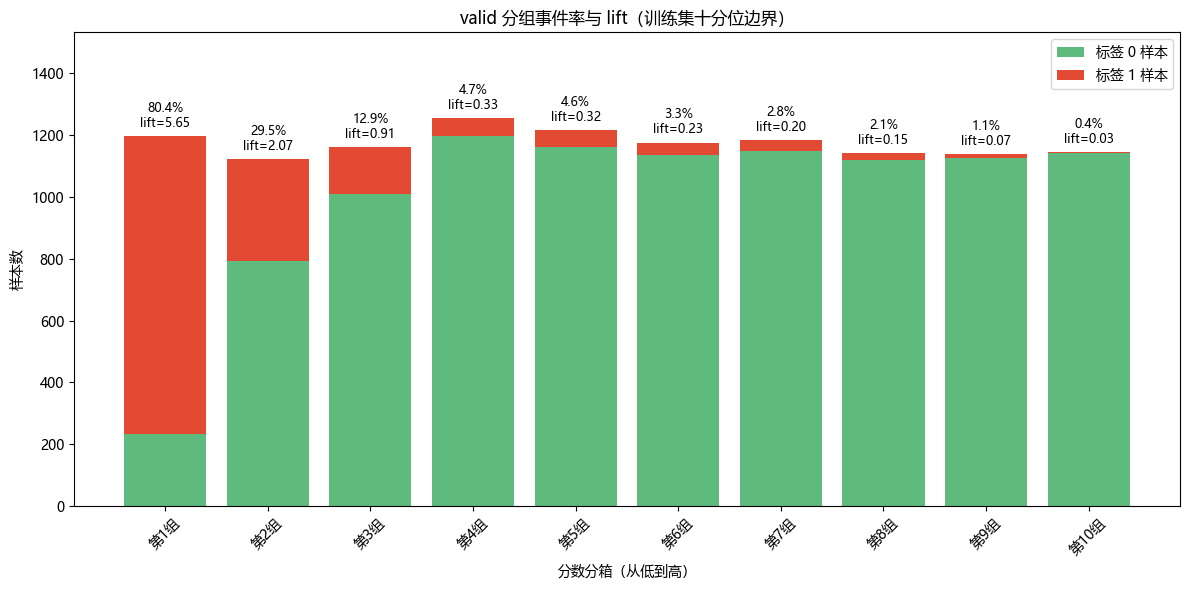


train 十分位报表：
           bin  样本数  事件数    事件率   lift
 (-inf, 378.0] 4705 3778 0.8030 5.6396
(378.0, 484.0] 4690 1372 0.2925 2.0546
(484.0, 539.0] 4729  539 0.1140 0.8005
(539.0, 579.0] 4687  294 0.0627 0.4406
(579.0, 618.0] 4648  232 0.0499 0.3506
(618.0, 657.0] 4748  183 0.0385 0.2707
(657.0, 698.0] 4687  133 0.0284 0.1993
(698.0, 739.0] 4703   88 0.0187 0.1314
(739.0, 786.0] 4710   41 0.0087 0.0611
  (786.0, inf] 4609   20 0.0043 0.0305

valid 十分位报表：
           bin  样本数  事件数    事件率   lift
 (-inf, 378.0] 1195  961 0.8042 5.6481
(378.0, 484.0] 1122  331 0.2950 2.0720
(484.0, 539.0] 1160  150 0.1293 0.9082
(539.0, 579.0] 1255   59 0.0470 0.3302
(579.0, 618.0] 1216   56 0.0461 0.3234
(618.0, 657.0] 1175   39 0.0332 0.2331
(657.0, 698.0] 1182   33 0.0279 0.1961
(698.0, 739.0] 1141   24 0.0210 0.1477
(739.0, 786.0] 1138   12 0.0105 0.0741
  (786.0, inf] 1145    5 0.0044 0.0307


In [ ]:
# 分界仅由训练集确定，验证集使用相同区间；两端覆盖新样本。
decile_edges = np.unique(np.quantile(train_score["score"], np.linspace(0, 1, 11)))
decile_edges[0], decile_edges[-1] = -np.inf, np.inf

def decile_report(df, score_col="score", y_col="loan_status", name="train", save=False):
    """应用训练集十分位边界，画堆叠图并返回事件率/lift 报表。"""
    tmp = df[[score_col, y_col]].copy()
    tmp["bin"] = pd.cut(tmp[score_col], bins=decile_edges, include_lowest=True)
    overall_bad = tmp[y_col].mean()                   # 整体坏率
    report = tmp.groupby("bin", observed=True).agg(
        样本数=(y_col, "count"),
        事件数=(y_col, "sum"),
        事件率=(y_col, "mean"),
    ).reset_index()
    report["lift"] = report["坏率"] / overall_bad

    good = report["样本数"] - report["事件数"]
    bad = report["事件数"]
    xpos = range(len(report))
    plt.figure(figsize=(12, 6))
    plt.bar(xpos, good, color="#5FBA7D", label="标签 0 样本")
    plt.bar(xpos, bad, bottom=good, color="#E24A33", label="标签 1 样本")
    for i in xpos:
        plt.text(i, report["样本数"].iloc[i] + 30,
                 f"{report['事件率'].iloc[i]:.1%}\nlift={report['lift'].iloc[i]:.2f}",
                 ha="center", fontsize=9)
    plt.xticks(xpos, [f"第{i + 1}组" for i in xpos], rotation=45)
    plt.xlabel("分数分箱（从低到高）"); plt.ylabel("样本数")
    plt.title(f"{name} 分组坏率与 lift（训练集十分位边界）")
    plt.ylim(0, report["样本数"].max() * 1.22)
    plt.legend(); plt.tight_layout()
    if save:
        plt.savefig(FIG_DIR / f"{name}_decile.png", dpi=150, bbox_inches="tight")
    finish_plot()
    return report

report_train = decile_report(train_score, name="train", save=True)
report_valid = decile_report(valid_score, name="valid", save=True)
print("\ntrain 十分位报表：")
print(report_train.round(4).to_string(index=False))
print("\nvalid 十分位报表：")
print(report_valid.round(4).to_string(index=False))

## 18. 分数分布可视化

标签 1 样本整体分数更低，符合评分方向。

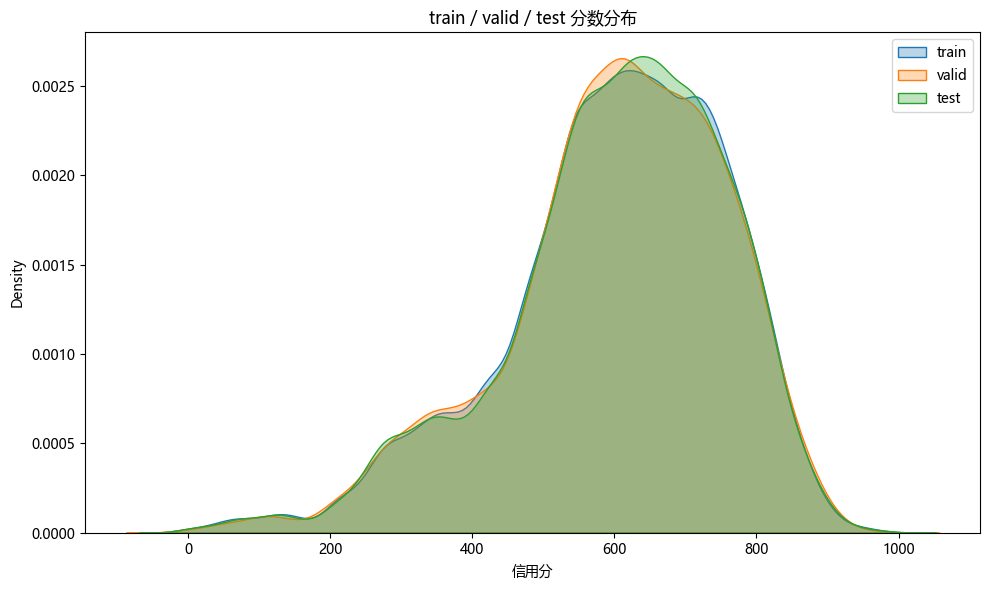

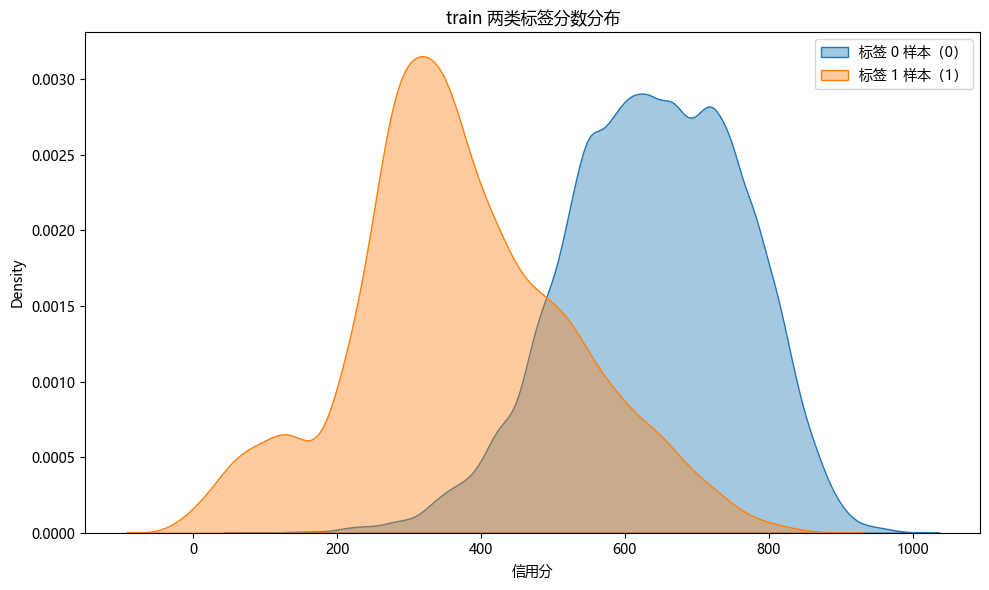

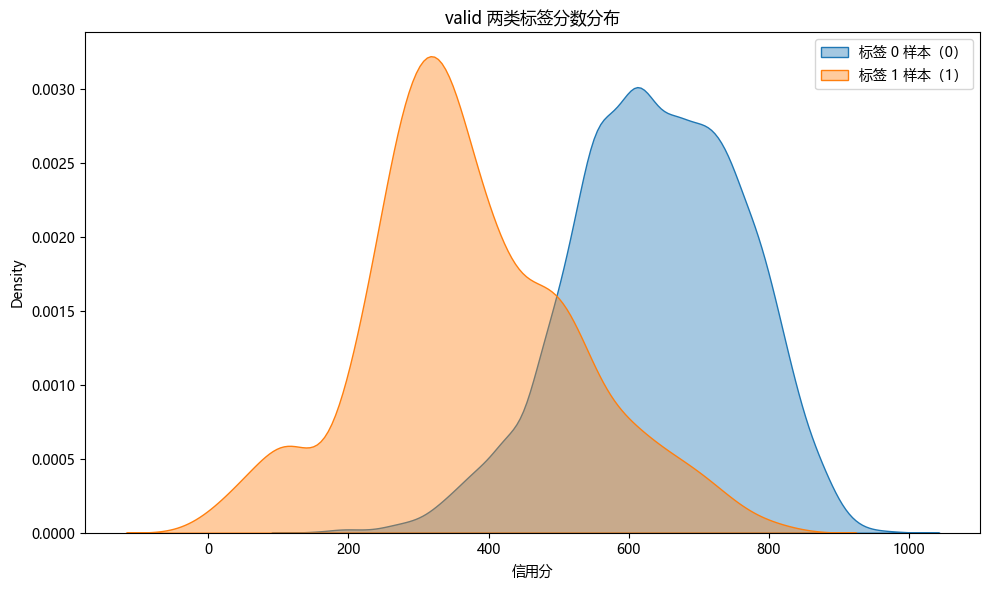

In [19]:
# 18.1 train / valid / test 三个集合的分数 KDE（同图）
plt.figure(figsize=(10, 6))
sns.kdeplot(train_score["score"], label="train", fill=True, alpha=0.3)
sns.kdeplot(valid_score["score"], label="valid", fill=True, alpha=0.3)
sns.kdeplot(test_score["score"], label="test", fill=True, alpha=0.3)
plt.xlabel("信用分"); plt.title("train / valid / test 分数分布")
plt.legend(); plt.tight_layout()
plt.savefig(FIG_DIR / "score_dist_3sets.png", dpi=150, bbox_inches="tight")
finish_plot()

# 18.2 两类标签的分数分布对比（train 和 valid 各一张）
def plot_score_by_label(df, y_col="loan_status", score_col="score", name="train", save=False):
    """输入含分数与标签的表，画两类标签的分数分布对比图。"""
    plt.figure(figsize=(10, 6))
    sns.kdeplot(df[df[y_col] == 0][score_col], label="标签 0 样本（0）", fill=True, alpha=0.4)
    sns.kdeplot(df[df[y_col] == 1][score_col], label="标签 1 样本（1）", fill=True, alpha=0.4)
    plt.xlabel("信用分"); plt.title(f"{name} 两类标签分数分布")
    plt.legend(); plt.tight_layout()
    if save:
        plt.savefig(FIG_DIR / f"{name}_score_by_label.png", dpi=150, bbox_inches="tight")
    finish_plot()

plot_score_by_label(train_score, name="train", save=True)
plot_score_by_label(valid_score, name="valid", save=True)

## 19. 阈值与评级示例（）

In [ ]:
# 19.1 分数与概率的换算（与 scorecardpy 的公式保持一致）
# scorecardpy：b = pdo / ln(2)，a = points0 + b * ln(odds0)，其中 odds = p/(1-p)
# 总分 = basepoints + Σ 变量分 = a - b * ln(p/(1-p))，概率越高分数越低
factor = PDO / np.log(2)                          # b：好/坏比翻倍增加的分
offset = POINTS0 + factor * np.log(ODDS0)         # a：基准分对应的偏移

def prob_to_score(p):
    """输入标签 1 概率，按评分卡的基准分/基准odds/pdo 换算成信用分。"""
    p = np.clip(np.asarray(p, dtype=float), 1e-10, 1 - 1e-10)
    return offset - factor * np.log(p / (1 - p))

# 校验：公式分数应与 scorecardpy 实际分数一致（只差整数取整误差）
score_from_prob = prob_to_score(valid_prob)
print("公式分数与实际分数的相关系数：",
      np.corrcoef(score_from_prob, valid_score["score"])[0, 1])

score_abs_error = np.abs(score_from_prob - valid_score["score"].to_numpy())
# 截距及每个变量分别取整，每项最多误差 0.5 分。
rounding_bound = 0.5 * (len(selected_vars) + 1)
assert score_abs_error.max() <= rounding_bound + 1e-8
print("评分换算最大绝对误差：", score_abs_error.max())

# 19.2 两种切分点：KS 最大处概率反推 vs 分位数法（通过率 70%）
score_cut_ks = prob_to_score(valid_ks_thr)
score_cut_pass70 = np.quantile(train_score["score"], 0.30)   
print(f"\nKS 最大处概率 {valid_ks_thr:.4f} 反推的分数切分点：{score_cut_ks:.1f}")
print(f"目标通过率约 70%（分数 30% 分位）的切分点：{score_cut_pass70:.1f}")
print(f"两种方法差异：{abs(score_cut_ks - score_cut_pass70):.1f} 分")

threshold_report = pd.DataFrame([
    {"dataset": name, "threshold": float(score_cut_pass70),
     "pass_rate": float((frame.score >= score_cut_pass70).mean()),
     "accepted_event_rate": float(frame.loc[frame.score >= score_cut_pass70, target].mean())}
    for name, frame in [("train", train_score), ("valid", valid_score)]
])
print("模拟规则 score >= 阈值：")
print(threshold_report)

# 19.3 把分数映射成 A~E 五档（分数越高评级越好）
grades = ["E", "D", "C", "B", "A"]   # 从低到高对应分数由低到高
train_score["grade"], grade_edges = pd.qcut(
    train_score["score"], q=5, labels=grades, retbins=True, duplicates="drop"
)
grade_edges = list(grade_edges)
grade_edges[0], grade_edges[-1] = -np.inf, np.inf   # 边界补成正负无穷
valid_score["grade"] = pd.cut(valid_score["score"], bins=grade_edges, labels=grades)

# 19.4 在 valid 上输出每个评级的人数 + 事件率，检查单调性
grade_report = valid_score.groupby("grade", observed=True).agg(
    人数=("loan_status", "count"),
    事件数=("loan_status", "sum"),
    事件率=("loan_status", "mean"),
).reindex(grades)
print("\nvalid 各评级人数与事件率：")
print(grade_report.round(4))
print("单调性检查（A 级事件率应最低，E 级最高）：",
      "通过" if grade_report["事件率"].is_monotonic_decreasing else "未通过")

公式分数与实际分数的相关系数： 0.9999930479559221
评分换算最大绝对误差： 2.6526791304463586

KS 最大处概率 0.1534 反推的分数切分点：507.1
目标通过率约 70%（分数 30% 分位）的切分点：539.0
两种方法差异：31.9 分
模拟规则 score >= 阈值：
  dataset  threshold  pass_rate  accepted_event_rate
0   train      539.0   0.700827             0.030292
1   valid      539.0   0.706198             0.028130

valid 各评级人数与事件率：
         人数   事件数     事件率
grade                    
E      2317  1292  0.5576
D      2415   209  0.0865
C      2391    95  0.0397
B      2323    57  0.0245
A      2283    17  0.0074
单调性检查（A 级事件率应最低，E 级最高）： 通过


## 20. PSI 分数分布对比


In [21]:
def calc_psi(expected, actual, bins=10):
    """输入基准分数与实际分数，按等宽分箱计算 PSI，返回 PSI 值。"""
    # 固定训练集等宽边界，同一基准与不同样本比较时保持可比。
    edges = np.linspace(expected.min(), expected.max(), bins + 1)
    edges[0], edges[-1] = -np.inf, np.inf
    e_ratio = np.histogram(expected, edges)[0] / len(expected)   # 基准（训练集）
    a_ratio = np.histogram(actual, edges)[0] / len(actual)       # 对比集
    e_ratio = np.clip(e_ratio, 1e-6, None)   # 避免 0 导致 log 报错
    a_ratio = np.clip(a_ratio, 1e-6, None)
    e_ratio /= e_ratio.sum()
    a_ratio /= a_ratio.sum()
    return float(np.sum((a_ratio - e_ratio) * np.log(a_ratio / e_ratio)))

def psi_conclusion(psi):
    """根据常用经验阈值描述分布差异，不作为时间外稳定性结论。"""
    if psi < 0.1:
        return "分布差异较小"
    elif psi < 0.25:
        return "需要关注"
    else:
        return "分布差异较大"

psi_train_valid = calc_psi(train_score["score"], valid_score["score"])
psi_train_test = calc_psi(train_score["score"], test_score["score"])
print(f"PSI(train vs valid) = {psi_train_valid:.4f} → {psi_conclusion(psi_train_valid)}")
print(f"PSI(train vs test)  = {psi_train_test:.4f} → {psi_conclusion(psi_train_test)}")

PSI(train vs valid) = 0.0011 → 分布差异较小
PSI(train vs test)  = 0.0004 → 分布差异较小


## 21. 导出交付物

评分卡表放入 reports，逐样本分数放入 outputs。逐样本文件默认不提交 GitHub。

In [22]:
# 21.1 评分卡表（每个变量一行一条分箱规则 + 分值）
scorecard_table = pd.concat(card.values(), ignore_index=True)
scorecard_table.to_csv(TABLE_DIR / "scorecard.csv", index=False, encoding="utf-8-sig")
print("已导出评分卡表 scorecard.csv，前几行：")
print(scorecard_table.head())

# 21.2 分数 CSV（id + score）
train_score["id"] = df_train["id"].values
valid_score["id"] = df_valid["id"].values
test_score["id"] = df_test["id"].values

train_score[["id", "score"]].to_csv(OUTPUT_DIR / "train_score.csv", index=False, encoding="utf-8-sig")
valid_score[["id", "score"]].to_csv(OUTPUT_DIR / "valid_score.csv", index=False, encoding="utf-8-sig")
test_score[["id", "score"]].to_csv(OUTPUT_DIR / "test_score.csv", index=False, encoding="utf-8-sig")
print("已导出 train_score.csv / valid_score.csv / test_score.csv（含 id + score）")

已导出评分卡表 scorecard.csv，前几行：
        variable                 bin  points
0     basepoints                 NaN   523.0
1  person_income      [-inf,35000.0)   -53.0
2  person_income   [35000.0,60000.0)    -7.0
3  person_income   [60000.0,80000.0)    21.0
4  person_income  [80000.0,120000.0)    51.0


已导出 train_score.csv / valid_score.csv / test_score.csv（含 id + score）


## 22. Kaggle 提交

生成符合 Kaggle 格式的概率文件，。同时保存指标、分箱、系数、环境信息和评分校验结果，便于复核。

In [ ]:
# 用模型预测标签 1 概率，clf是上面的LR模型。
test_prob = clf.predict_proba(x_test[selected_vars])[:, 1]

submission = pd.DataFrame({
    "id": df_test["id"].values,
    "loan_status": test_prob,
})

# 校验：行数一致、id 顺序一致、概率在 [0,1] 之间
assert submission.shape[0] == df_test.shape[0], "行数与 test.csv 不一致"
assert (submission["id"].values == df_test["id"].values).all(), "id 顺序与 test.csv 不一致"
assert submission["loan_status"].between(0, 1).all(), "loan_status 超出 [0,1]"

print("校验通过：行数 =", submission.shape[0],
      "，id 对齐 =", (submission["id"].values == df_test["id"].values).all(),
      "，loan_status ∈ [0,1] =", submission["loan_status"].between(0, 1).all())
print("\nsubmission.csv 前 5 行：")
print(submission.head())
print("submission shape =", submission.shape)

submission.to_csv(OUTPUT_DIR / "submission.csv", index=False)
print("已导出 submission.csv")

pd.concat(bins.values(), ignore_index=True).to_csv(TABLE_DIR / "woe_bins.csv", index=False)
for name, frame, scores, probabilities in [
    ("train", df_train, train_score, train_prob),
    ("valid", df_valid, valid_score, valid_prob),
]:
    assert scores.index.equals(frame.index), "评分与样本索引未对齐"
    pd.DataFrame({"id": frame.id.to_numpy(), target: frame[target].to_numpy(),
                  "probability": probabilities, "score": scores.score.to_numpy()}).to_csv(
                      OUTPUT_DIR / f"{name}_predictions.csv", index=False)
print("结果已保存：reports/figures、reports/tables、outputs")

校验通过：行数 = 39098 ，id 对齐 = True ，loan_status ∈ [0,1] = True

submission.csv 前 5 行：
      id  loan_status
0  58645     0.983368
1  58646     0.009263
2  58647     0.547244
3  58648     0.036379
4  58649     0.215568
submission shape = (39098, 2)
已导出 submission.csv


结果已保存：reports/figures、reports/tables、outputs
